# 🎓 MSc in Artificial Intelligence & Deep Learning
## Course: AIDL_03 — Platforms for AI and Python programming
### Project: NBA Player Performance & Salary Analysis (2010–2025)

**Student:** Fotis Papadopoulos  
**Student ID:** aidl_0114  
**Professor:** Grigoris Nikolaou  
**Date:** June 2026

# 1. Introduction & Data Source Citation

This project conducts an Exploratory Data Analysis (EDA) on an NBA player dataset combining performance statistics and salary records from 2010 to 2025.

## Data Citation:
* **Primary Statistics:** Sourced from *Basketball-Reference*.
* **Historical Salaries:** Sourced from *HoopsHype*.
* **Merged Dataset:** Compiled by programmer Edwin Jeon and made available via the GitHub repository [`edwinjeon/NBA-Salary-Prediction`](https://github.com/edwinjeon/NBA-Salary-Prediction).

# 2. Initial Data Inspection

## 2.1 Dataset Loading & Initial Setup
We load the merged NBA statistics and salary dataset directly from the public GitHub repository to ensure a self-contained, reproducible analysis.

In [ ]:
import pandas as pd

# Direct public URL to the dataset
url = "https://raw.githubusercontent.com/edwinjeon/NBA-Salary-Prediction/main/data/NBA%20Player%20Stats%20and%20Salaries_2010-2025.csv"

# Load the dataset into a Pandas DataFrame
df = pd.read_csv(url)

# Display the dimensions (shape) of the loaded dataset
print(f"Dataset successfully loaded! Shape: {df.shape}")

Dataset successfully loaded! Shape: (7298, 31)


## 2.2 Dataset Variables & Initial Inspection
Before formulating our research questions, we perform a quick inspection of the columns and data types available in the dataset.

In [ ]:
# Inspect the column names and data types
print("Columns in the dataset:")
print(df.columns.tolist())

print("\nDataset Info Summary:")
df.info()

print("\nFirst rows of the dataset:")
df.head()

Columns in the dataset:
['Player', 'Salary', 'Year', 'Pos', 'Age', 'Team', 'G', 'GS', 'MP', 'FG', 'FGA', 'FG%', '3P', '3PA', '3P%', '2P', '2PA', '2P%', 'eFG%', 'FT', 'FTA', 'FT%', 'ORB', 'DRB', 'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS']

Dataset Info Summary:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7298 entries, 0 to 7297
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Player  7298 non-null   object 
 1   Salary  7298 non-null   int64  
 2   Year    7298 non-null   int64  
 3   Pos     7298 non-null   object 
 4   Age     7298 non-null   int64  
 5   Team    7298 non-null   object 
 6   G       7298 non-null   int64  
 7   GS      7298 non-null   int64  
 8   MP      7298 non-null   float64
 9   FG      7298 non-null   float64
 10  FGA     7298 non-null   float64
 11  FG%     7278 non-null   float64
 12  3P      7298 non-null   float64
 13  3PA     7298 non-null   float64
 14  3P%     6713 non-null   float64

,Player,Salary,Year,Pos,Age,Team,G,GS,MP,FG,...,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS
0,Kobe Bryant,23034375,2010,SG,31,LAL,73,73,38.8,9.8,...,0.811,1.1,4.3,5.4,5.0,1.5,0.3,3.2,2.6,27.0
1,Jermaine O'Neal,23016000,2010,C,31,MIA,70,70,28.4,5.6,...,0.720,1.8,5.2,6.9,1.3,0.4,1.4,1.8,3.0,13.6
2,Tracy McGrady,22843124,2010,SG,30,NYK,30,24,22.4,3.0,...,0.746,0.7,2.4,3.1,3.3,0.5,0.5,1.5,1.3,8.2
3,Tim Duncan,22183220,2010,C,33,SAS,78,77,31.3,7.2,...,0.725,2.8,7.3,10.1,3.2,0.6,1.5,1.8,1.9,17.9
4,Shaquille O'Neal,21000000,2010,C,37,CLE,53,53,23.4,4.9,...,0.496,1.8,4.9,6.7,1.5,0.3,1.2,2.0,3.2,12.0


# 3. Posed Initial Questions

Before starting the Exploratory Data Analysis, we formally define our three initial, non-overlapping research questions designed to uncover distinct and valuable insights:

1. **Question 1 (Categorical Grouping):** How do the distribution and median profiles of player salaries differ across the five traditional playing positions (`Pos`)?
2. **Question 2 (Feature Engineering):** If we engineer a new "Scoring Profile" category (e.g., Bench, Role Player, Star) based on minutes played (`MP`), how do their average points per minute compare?
3. **Question 3 (Correlation Analysis):** Which metric has a stronger correlation with player salary: shooting volume (`FGA`) or shooting efficiency (`eFG%`)?

# 4. Deep Data Quality & Preprocessing (Lab 7 Alignment)
We thoroughly evaluate the quality, format, structure, and integrity of the NBA dataset.

## 4.1 Dataset Format & Structure
We inspect the dataset's structural dimensions, layout, and memory usage.

In [ ]:
# 1. print the shape
print(f"Dataset Shape: {df.shape}")

# 2. view data types and non-null counts of each column
print("\nDataset Structural Details:")
df.info()

Dataset Shape: (7298, 31)

Dataset Structural Details:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7298 entries, 0 to 7297
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Player  7298 non-null   object 
 1   Salary  7298 non-null   int64  
 2   Year    7298 non-null   int64  
 3   Pos     7298 non-null   object 
 4   Age     7298 non-null   int64  
 5   Team    7298 non-null   object 
 6   G       7298 non-null   int64  
 7   GS      7298 non-null   int64  
 8   MP      7298 non-null   float64
 9   FG      7298 non-null   float64
 10  FGA     7298 non-null   float64
 11  FG%     7278 non-null   float64
 12  3P      7298 non-null   float64
 13  3PA     7298 non-null   float64
 14  3P%     6713 non-null   float64
 15  2P      7298 non-null   float64
 16  2PA     7298 non-null   float64
 17  2P%     7253 non-null   float64
 18  eFG%    7278 non-null   float64
 19  FT      7298 non-null   float64
 20  FTA     7298 non-nu

## 4.2 Variables Included in the Dataset
We list the specific features and categorize them into numerical and categorical variables.

In [ ]:
# 1. print all variables as a list
all_cols = df.columns.tolist()
print("All Variables:")
print(all_cols)

# 2. get and print list of numerical columns
num_cols = df.select_dtypes(include=['number']).columns.tolist()
print(f"\nNumerical Variables ({len(num_cols)}):")
print(num_cols)

# 3. get and print list of categorical (text) columns
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
print(f"\nCategorical Variables ({len(cat_cols)}):")
print(cat_cols)

# 4. Check how many of them are categorical and how many are numerical
print(f"\nNumerical Variables are {len(num_cols)} and Categorical Variables are {len(cat_cols)}.")

All Variables:
['Player', 'Salary', 'Year', 'Pos', 'Age', 'Team', 'G', 'GS', 'MP', 'FG', 'FGA', 'FG%', '3P', '3PA', '3P%', '2P', '2PA', '2P%', 'eFG%', 'FT', 'FTA', 'FT%', 'ORB', 'DRB', 'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS']

Numerical Variables (28):
['Salary', 'Year', 'Age', 'G', 'GS', 'MP', 'FG', 'FGA', 'FG%', '3P', '3PA', '3P%', '2P', '2PA', '2P%', 'eFG%', 'FT', 'FTA', 'FT%', 'ORB', 'DRB', 'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS']

Categorical Variables (3):
['Player', 'Pos', 'Team']

Numerical Variables are 28 and Categorical Variables are 3.


## 4.3 Data Distributions
We compute descriptive statistics for numerical columns, frequency counts for categorical variables, and visualize their distributions.

In [ ]:
# 1. print the statistical summary table of numerical variables
print("Descriptive Statistics for Numerical Features:")
display(df.describe())

# 2. print the distribution frequency for categorical player positions
print("\nPlayer Count by Position (Pos):")
print(df['Pos'].value_counts())

# Select only numerical columns
numeric_cols = df.select_dtypes(include=['number'])

# Calculate the Coefficient of Variation (Standard Deviation / Mean) for each column
cv_series = numeric_cols.std() / numeric_cols.mean()

# Sort the CV values from maximum to minimum
cv_sorted = cv_series.sort_values(ascending=False)
print("Coefficient of Variation (CV) Sorted (Max to Min):")
display(cv_sorted.to_frame(name='CV').round(4))

Descriptive Statistics for Numerical Features:


,Salary,Year,Age,G,GS,MP,FG,FGA,FG%,3P,...,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS
count,7.298000e+03,7298.000000,7298.000000,7298.000000,7298.000000,7298.000000,7298.000000,7298.000000,7278.000000,7298.000000,...,7096.000000,7298.000000,7298.000000,7298.000000,7298.000000,7298.000000,7298.000000,7298.000000,7298.000000,7298.000000
mean,6.483666e+06,2017.712661,26.226500,51.086599,24.665388,20.397260,3.246725,7.133297,0.447199,0.812332,...,0.733668,0.906235,2.750671,3.654563,1.961428,0.647150,0.415991,1.152987,1.739435,8.741628
std,8.553267e+06,4.634517,4.254263,23.843775,27.745206,9.341152,2.224763,4.653215,0.096594,0.804948,...,0.153363,0.790554,1.797460,2.435910,1.845592,0.416783,0.426520,0.805500,0.751550,6.156273
min,2.692000e+03,2010.000000,19.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.183646e+06,2014.000000,23.000000,33.000000,1.000000,13.000000,1.500000,3.500000,0.405000,0.100000,...,0.669750,0.400000,1.500000,1.900000,0.700000,0.300000,0.100000,0.600000,1.200000,4.100000
50%,3.010634e+06,2018.000000,25.500000,57.000000,11.000000,20.100000,2.700000,6.100000,0.444000,0.600000,...,0.761000,0.700000,2.400000,3.100000,1.300000,0.600000,0.300000,1.000000,1.800000,7.200000
75%,8.249162e+06,2022.000000,29.000000,71.000000,49.000000,28.200000,4.500000,9.800000,0.491000,1.300000,...,0.828000,1.200000,3.600000,4.700000,2.600000,0.900000,0.500000,1.500000,2.300000,12.000000
max,5.576122e+07,2025.000000,43.000000,84.000000,83.000000,43.500000,11.800000,24.500000,1.000000,5.300000,...,1.000000,5.500000,11.400000,16.000000,11.700000,3.000000,3.800000,5.700000,5.000000,36.100000



Player Count by Position (Pos):
Pos
SG       1628
PF       1441
C        1408
PG       1358
SF       1334
SF-SG      19
SG-PG      18
SG-SF      16
PF-SF      16
PG-SG      16
PF-C       14
C-PF       14
SF-PF      13
SG-PF       2
SF-C        1
Name: count, dtype: int64
Coefficient of Variation (CV) Sorted (Max to Min):


,CV
Salary,1.3192
GS,1.1249
BLK,1.0253
3P,0.9909
FT,0.9640
AST,0.9409
3PA,0.9083
FTA,0.9048
ORB,0.8724
2P,0.7729


In [ ]:
# This part was made to see the range of the salary, as initially when I printed the salary distribution it split starting from 0 million, were most of the players were concentrated as they were paid hundreds of thousands.
# So this was done to calculate the range of the salary column and then manually decide the start and the end of the intervals in the salary distribution plot which you see in the next code section
min_salary = df['Salary'].min()
max_salary = df['Salary'].max()

print(f"Minimum Salary: ${min_salary:,}")
print(f"Maximum Salary: ${max_salary:,}")

Minimum Salary: $2,692
Maximum Salary: $55,761,216


/tmp/ipykernel_14789/63824168.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='Pos', data=df, ax=axes[1], order=df['Pos'].value_counts().index, palette='viridis')


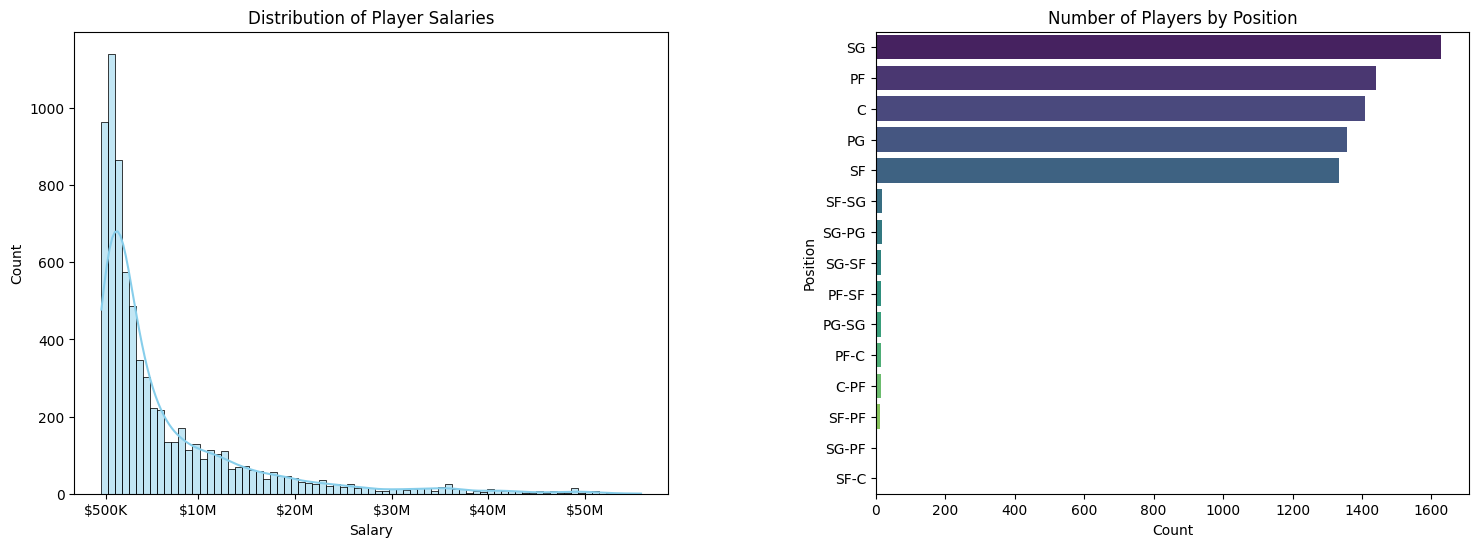

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Helper function to dynamically format tick labels
def format_salary(x, pos):
    if x >= 1e6: # -> 1e6 is 1.000.000, it is like saying 1 * 10^6
        val = x * 1e-6 # -> this one is like saying 1 * 10^(-6)
        return f"${val:.1f}M".replace(".0M", "M") # :.1f, means round it to one decimal and treat like float (primary python data type), if it is a clean integer like e.g. 10.0M, we just replace the '0M' to just 'M'
    elif x >= 1e3:
        return f"${x*1e-3:.0f}K" # -> here we don't need the decimals for the hundreds of thousands
    # this option doesn't exist in our dataset but we included it to be more precise programmatically
    else:
        return f"${x:.0f}"

# Create subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(18, 6)) # Increased width slightly for horizontal space

# 1. Salary distribution (Histogram & KDE)
sns.histplot(x='Salary', data=df, kde=True, ax=axes[0], color='skyblue')

axes[0].set_title('Distribution of Player Salaries')
axes[0].set_xlabel('Salary')
custom_ticks = [500000, 10000000, 20000000, 30000000, 40000000, 50000000]
axes[0].set_xticks(custom_ticks)
axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(format_salary))

# 2. Count of players by position (Horizontal Countplot as the x labels were overlapping in the vertical bar plot)
sns.countplot(y='Pos', data=df, ax=axes[1], order=df['Pos'].value_counts().index, palette='viridis')
axes[1].set_title('Number of Players by Position')
axes[1].set_xlabel('Count')
axes[1].set_ylabel('Position')

plt.subplots_adjust(wspace=0.35)
plt.show()

## 4.4 Notable Data Quality Issues
We systematically inspect our dataset for three major quality criteria: missing values, duplicate records, and extreme numerical outliers.

In [ ]:
# 1. check for missing values in each column
print("Missing Values per Column:")
null_counts = df.isnull().sum()
print(null_counts[null_counts > 0]) # Show only columns with at least 1 null value
# 2. check for duplicate rows
duplicates = df.duplicated().sum()
print(f"\nNumber of Duplicate Rows: {duplicates}")

Missing Values per Column:
FG%      20
3P%     585
2P%      45
eFG%     20
FT%     202
dtype: int64

Number of Duplicate Rows: 0


In [ ]:
# 3. check salary outliers using the IQR (Interquartile Range) method
Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df['Salary'] < lower_bound) | (df['Salary'] > upper_bound)]
print(f"\nSalary Outlier Analysis:")
print(f"  IQR range: ${Q1:,.0f} to ${Q3:,.0f} (IQR: ${IQR:,.0f})") # the comma adds commas to thousands, so for example 10000 becomes 10,000, so that it is easier to understand
print(f"  Upper Outlier Boundary: > ${upper_bound:,.0f}  -  Lower Outlier Boundary: < ${lower_bound:,.0f}")
print(f"  Number of Salary Outliers: {len(outliers)} ({len(outliers)/len(df):.2%} of the dataset)")


Salary Outlier Analysis:
  IQR range: $1,183,646 to $8,249,162 (IQR: $7,065,516)
  Upper Outlier Boundary: > $18,847,436  -  Lower Outlier Boundary: < $-9,414,628
  Number of Salary Outliers: 611 (8.37% of the dataset)


### Data Quality Insight: Midseason Trades & Duplicate Names
* **Midseason Trades:** The dataset has been pre-cleaned by the original compiler. For players traded midseason (e.g., James Harden in 2021), only a single row is preserved, representing their final team and consolidated season statistics.
* **Name Anomalies:** The duplicate check yields only 4 records. These are not duplicates, but rather two pairs of completely different active players who happen to share identical names (Chris Johnson in 2013 and Tony Mitchell in 2014).

In [ ]:
# 4. check for players with multiple rows in the same year (traded midseason)
traded_players = df.groupby(['Player', 'Year']).filter(lambda x: len(x) > 1)
print(traded_players.head())
print(f"\nNumber of traded player-season records: {len(traded_players)}")

# check how midseason trades are handled using James Harden's 2021 trade season
harden_2021 = df[(df['Player'] == 'James Harden') & (df['Year'] == 2021)]
print("James Harden 2021 Season Record:")
display(harden_2021[['Player', 'Year', 'Team', 'Salary', 'G', 'PTS']])

             Player  Salary  Year Pos  Age Team   G  GS    MP   FG  ...  \
1745  Chris Johnson   55718  2013  SF   22  MEM   8   0  12.8  1.4  ...   
1746  Chris Johnson   55718  2013   C   27  MIN  30   0   9.5  1.6  ...   
2113  Tony Mitchell  500000  2014  PF   21  DET  21   0   3.8  0.2  ...   
2114  Tony Mitchell  500000  2014  SF   24  MIL   3   0   3.3  1.0  ...   

        FT%  ORB  DRB  TRB  AST  STL  BLK  TOV   PF  PTS  
1745  0.500  0.6  0.8  1.4  0.3  0.5  0.0  0.4  0.6  3.6  
1746  0.618  0.7  1.3  2.0  0.3  0.2  0.9  0.4  1.6  3.9  
2113  0.579  0.7  0.5  1.2  0.1  0.3  0.1  0.2  0.4  1.0  
2114    NaN  0.3  0.0  0.3  0.3  0.3  0.0  0.0  0.0  2.0  

[4 rows x 31 columns]

Number of traded player-season records: 4
James Harden 2021 Season Record:


,Player,Year,Team,Salary,G,PTS
4827,James Harden,2021,BRK,50277018,44,24.6


## 4.5 Relationships Between Variables
We explore how our variables relate to one another, comparing numerical metrics against categorical features and calculating correlations.

/tmp/ipykernel_14789/2685499054.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y='Pos', x='Salary', data=df, ax=axes[0], order=df['Pos'].value_counts().index, palette='viridis')


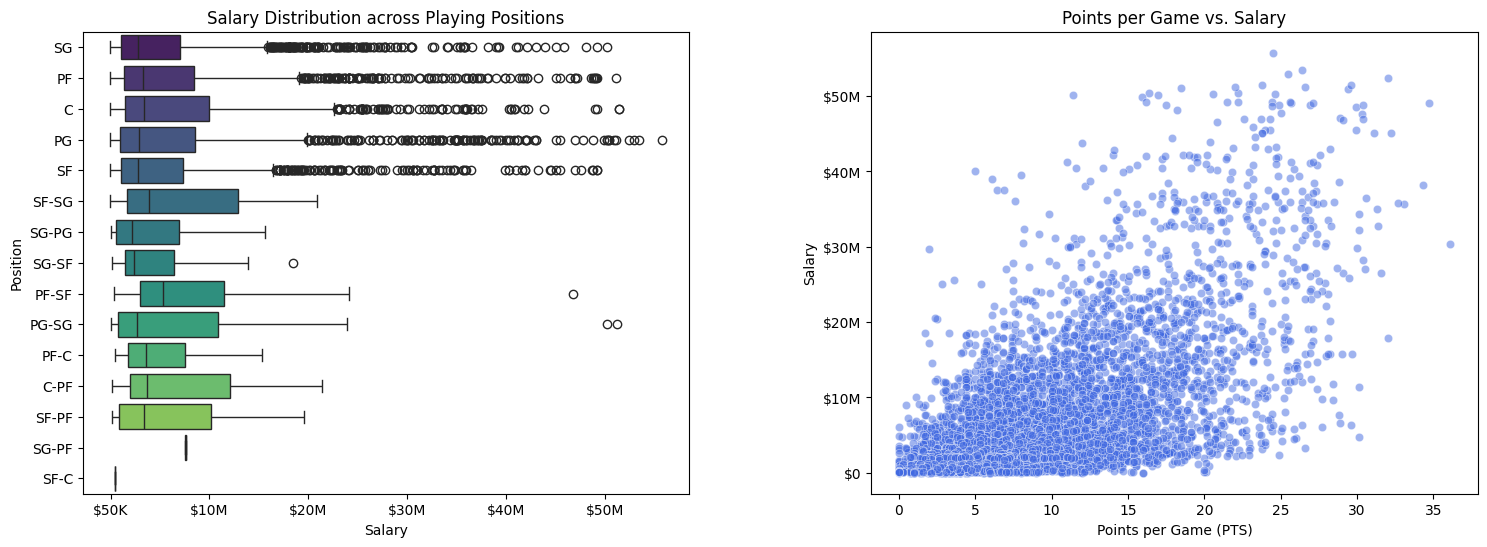

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# helper function to dynamically format tick labels in Millions/Thousands
# this is done, so that the first label in the x axis is not 0, since the default split of the x axis resulted in 5 bins of length 10 million,
# and the first x values in the x - axis was 0, so that would confuse the person looking at the graph, so made it to be 50K (50000$ which is a very rare yearly contract in the NBA)
def format_salary(x, pos):
    if x >= 1e6:
        val = x * 1e-6
        return f"${val:.1f}M".replace(".0M", "M") # -> in case we don't have any decimals we want only the integer to be shown
    elif x >= 1e3:
        return f"${x*1e-3:.0f}K"
    else:
        return f"${x:.0f}"

# Create subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 1. Salary vs Position (Horizontal Boxplot - clean spacing)
sns.boxplot(y='Pos', x='Salary', data=df, ax=axes[0], order=df['Pos'].value_counts().index, palette='viridis')
axes[0].set_title('Salary Distribution across Playing Positions')
axes[0].set_xlabel('Salary')
axes[0].set_ylabel('Position')
custom_ticks = [50000, 10000000, 20000000, 30000000, 40000000, 50000000]
axes[0].set_xticks(custom_ticks)
axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(format_salary))

# 2. Points vs Salary (Scatterplot)
sns.scatterplot(x='PTS', y='Salary', data=df, ax=axes[1], alpha=0.5, color='royalblue')
axes[1].set_title('Points per Game vs. Salary')
axes[1].set_xlabel('Points per Game (PTS)')
axes[1].set_ylabel('Salary')
axes[1].yaxis.set_major_formatter(ticker.FuncFormatter(format_salary))

plt.subplots_adjust(wspace=0.3)
plt.show()

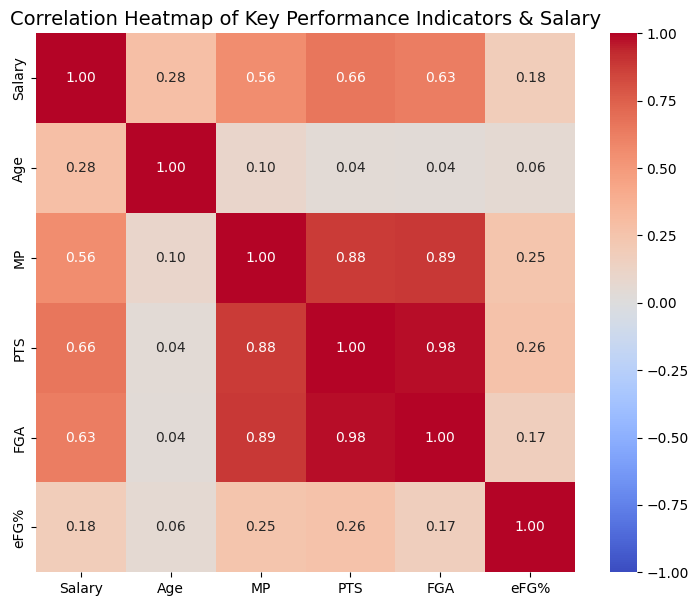

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only the 6 key variables related to our research questions
targeted_metrics = ['Salary', 'Age', 'MP', 'PTS', 'FGA', 'eFG%']

# Calculate the Pearson correlation matrix
targeted_corr = df[targeted_metrics].corr()

# Plot a beautiful, clean, smaller heatmap (8x7 inches)
plt.figure(figsize=(9, 7))
sns.heatmap(targeted_corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, square=True) # annot makes the plot to display the correlation number inside the box, vmin and vmax are the boundaries for the scale

plt.title('Correlation Heatmap of Key Performance Indicators & Salary', fontsize=14)
plt.show()

## 4.6 Patterns & Anomalies
We use statistical grouping to identify general performance patterns across playing positions, and locate extreme anomaly records (like the maximum salary and scoring seasons) in our dataset.

In [ ]:
# 1. Patterns: Group by position to see average Salary, Minutes Played (MP), and Points (PTS)
print("Position-Based Patterns (Averages):")
position_patterns = df.groupby('Pos')[['Salary', 'MP', 'PTS']].mean()
display(position_patterns) # display is a built in function of the Jupyter Notebook (ipynb files)

# 2. Anomalies: Identify the player with the absolute HIGHEST Salary in the entire dataset
max_salary_idx = df['Salary'].idxmax() # get the row index for the maximum value of salary
highest_paid = df.loc[max_salary_idx] # get the whole row based on the index above
print("\nExtreme Anomaly: Highest Paid Player Record:")
print(f"  Player: {highest_paid['Player']} ({highest_paid['Year']})")
print(f"  Team: {highest_paid['Team']} | Position: {highest_paid['Pos']}")
print(f"  Salary: ${highest_paid['Salary']:,} | Points: {highest_paid['PTS']} PPG")

# 3. Anomalies: Identify the player with the absolute HIGHEST Scoring Season in the dataset
max_pts_idx = df['PTS'].idxmax()
highest_scorer = df.loc[max_pts_idx]
print("\nExtreme Anomaly: Highest Scoring Season Record:")
print(f"  Player: {highest_scorer['Player']} ({highest_scorer['Year']})")
print(f"  Team: {highest_scorer['Team']} | Position: {highest_scorer['Pos']}")
print(f"  Salary: ${highest_scorer['Salary']:,} | Points: {highest_scorer['PTS']} PPG")

Position-Based Patterns (Averages):


,Salary,MP,PTS
Pos,,,
C,6.846741e+06,18.646662,7.794744
C-PF,6.934037e+06,18.171429,7.628571
PF,6.783908e+06,19.758779,8.442887
PF-C,4.997961e+06,17.592857,6.414286
PF-SF,9.441545e+06,22.775000,8.675000
PG,7.194427e+06,22.115464,9.925700
PG-SG,1.081627e+07,23.568750,11.168750
SF,6.005130e+06,20.703073,8.441754
SF-C,5.127210e+05,12.100000,3.600000



Extreme Anomaly: Highest Paid Player Record:
  Player: Stephen Curry (2025)
  Team: GSW | Position: PG
  Salary: $55,761,216 | Points: 24.5 PPG

Extreme Anomaly: Highest Scoring Season Record:
  Player: James Harden (2019)
  Team: HOU | Position: PG
  Salary: $30,421,854 | Points: 36.1 PPG


# 5. Non-Graphical Statistical Analysis
We perform mathematical and statistical evaluations to describe the numerical data and uncover patterns without relying on visual plots.

## 5.1 Non-Graphical Statistical Analysis on Key Variables
We calculate the variance, skewness, and kurtosis of our key performance indicator (`PTS`) and target variable (`Salary`) to understand their distribution shapes mathematically.

In [ ]:
# Calculate statistical shape metrics: Mean, Standard Deviation, Variance, Skewness, and Excess Kurtosis
for col in ['Salary', 'PTS']:
    mean = df[col].mean()
    std_dev = df[col].std()
    variance = df[col].var()
    skewness = df[col].skew()
    kurt = df[col].kurt() # Excess Kurtosis (Normal Distribution = 0)

    print(f"--- Statistical Summary for {col} ---")
    if col == 'Salary':
        print(f"  Mean: ${mean:,.2f}")
        print(f"  Standard Deviation: ${std_dev:,.2f}")
        print(f"  Variance: {variance:,.2f}")
    else:
        print(f"  Mean: {mean:.4f}")
        print(f"  Standard Deviation: {std_dev:.4f}")
        print(f"  Variance: {variance:.4f}")
    print(f"  Skewness: {skewness:.4f}")
    print(f"  Excess Kurtosis: {kurt:.4f}\n")

--- Statistical Summary for Salary ---
  Mean: $6,483,666.10
  Standard Deviation: $8,553,267.10
  Variance: 73,158,378,145,235.77
  Skewness: 2.4126
  Excess Kurtosis: 6.5567

--- Statistical Summary for PTS ---
  Mean: 8.7416
  Standard Deviation: 6.1563
  Variance: 37.8997
  Skewness: 1.0736
  Excess Kurtosis: 0.8592



## 5.2 Describing Data Distributions
We use non-graphical descriptive methods, focusing on percentile and quantile breakdowns, to mathematically describe the spread of player salaries and scoring performance.

In [ ]:
# Define the percentiles we want to examine (from 10th up to the 99th elite percentile)
percentiles = [0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

# Calculate the values at each percentile
salary_pcts = df['Salary'].quantile(percentiles)
pts_pcts = df['PTS'].quantile(percentiles)

# Print formatted results
print("--- Salary Percentile Distribution ---")
for pct, val in salary_pcts.items():
    print(f"  {int(pct*100)}th Percentile: ${val:,.2f}")

print("\n--- Points (PTS) Percentile Distribution ---")
for pct, val in pts_pcts.items():
    print(f"  {int(pct*100)}th Percentile: {val:.2f} PPG")

--- Salary Percentile Distribution ---
  10th Percentile: $534,959.00
  25th Percentile: $1,183,646.25
  50th Percentile: $3,010,633.50
  75th Percentile: $8,249,162.25
  90th Percentile: $17,135,555.00
  95th Percentile: $24,594,497.00
  99th Percentile: $41,323,229.85

--- Points (PTS) Percentile Distribution ---
  10th Percentile: 2.20 PPG
  25th Percentile: 4.10 PPG
  50th Percentile: 7.20 PPG
  75th Percentile: 12.00 PPG
  90th Percentile: 17.70 PPG
  95th Percentile: 21.20 PPG
  99th Percentile: 27.10 PPG


## 5.3 Uncovering Underlying Patterns
We use statistical binning and cross-tabulation (non-graphical grouping) to analyze how players are distributed across career stages (Age) and financial brackets (Salary Tiers).

In [ ]:
# 1. make 3 age groups based on three logical career stages
age_bins = [0, 24, 30, 100]
age_labels = ['Young (<25)', 'Prime (25-30)', 'Veteran (>30)']
df['Age_Group'] = pd.cut(df['Age'], bins=age_bins, labels=age_labels)

# 2. Segment Salary into three financial brackets
salary_bins = [0, 2000000, 10000000, 100000000]
salary_labels = ['Low (<$2M)', 'Mid ($2M-$10M)', 'High (>$10M)']
df['Salary_Tier'] = pd.cut(df['Salary'], bins=salary_bins, labels=salary_labels)

# 3. Compute cross-tabulation (Counts of players in each intersection)
print("--- Raw Player Counts (Age Group vs. Salary Tier) ---")
crosstab_counts = pd.crosstab(df['Age_Group'], df['Salary_Tier'])
display(crosstab_counts)

# 4. Compute normalized cross-tabulation (Percentage of each age group in each tier)
print("\n--- Percentage Distribution within each Age Group (Row-wise %) ---")
crosstab_pct = pd.crosstab(df['Age_Group'], df['Salary_Tier'], normalize='index') * 100
display(crosstab_pct.round(1).astype(str) + '%')

--- Raw Player Counts (Age Group vs. Salary Tier) ---


Salary_Tier,Low (<$2M),Mid ($2M-$10M),High (>$10M)
Age_Group,,,
Young (<25),1515,1261,196
Prime (25-30),890,1255,922
Veteran (>30),312,542,405



--- Percentage Distribution within each Age Group (Row-wise %) ---


Salary_Tier,Low (<$2M),Mid ($2M-$10M),High (>$10M)
Age_Group,,,
Young (<25),51.0%,42.4%,6.6%
Prime (25-30),29.0%,40.9%,30.1%
Veteran (>30),24.8%,43.1%,32.2%


# 6. Exploratory Data Analysis: Exploring Initial Questions
We explore our three initial research questions by creating and refining target visualizations.

## 6.1 Question 1: Salary Distribution across Playing Positions
*Question:* How do the distribution and median profiles of player salaries differ across the five traditional playing positions (`Pos`)?

### 6.1.1 Initial Visualization & Insights
We create an initial boxplot to compare the median salaries and spread across the five primary playing positions. To preserve the raw data, we extract the primary position into a temporary column.

/tmp/ipykernel_14789/1234170383.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Primary_Pos', y='Salary', data=plot_df,


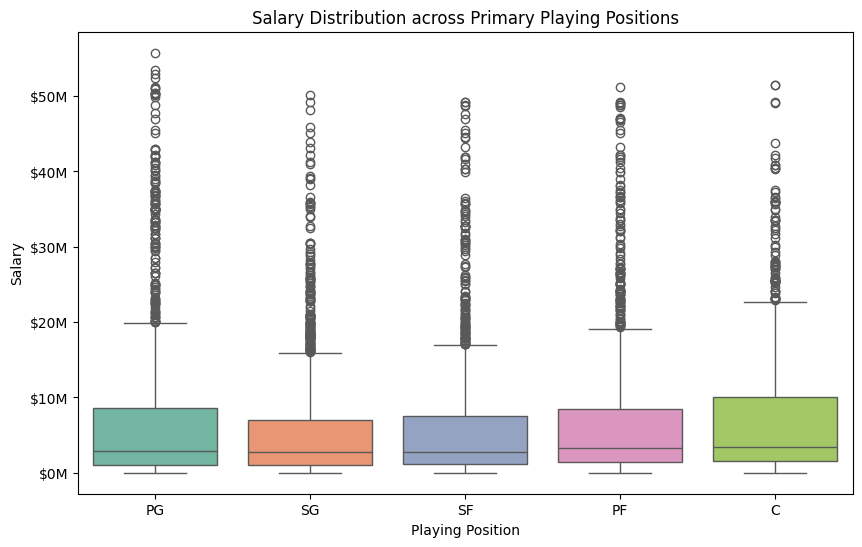

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Helper function to format salary on the Y-axis
def format_salary(x, pos):
    return f"${x*1e-6:.0f}M"

# Create a temporary column for primary position (handling hybrid positions like SF-SG)
plot_df = df.copy()
plot_df['Primary_Pos'] = plot_df['Pos'].str.split('-').str[0]

# Plot vertical boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(x='Primary_Pos', y='Salary', data=plot_df,
            order=['PG', 'SG', 'SF', 'PF', 'C'], palette='Set2')

plt.title('Salary Distribution across Primary Playing Positions')
plt.xlabel('Playing Position')
plt.ylabel('Salary')
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(format_salary))

plt.show()

### 6.1.2 Refined Visualization (Adding Age Group as a Variable)
We refine the visualization by introducing a second variable (`Age_Group`) to observe how the salary distributions across positions shift as players progress from young prospects to prime and veteran stages.

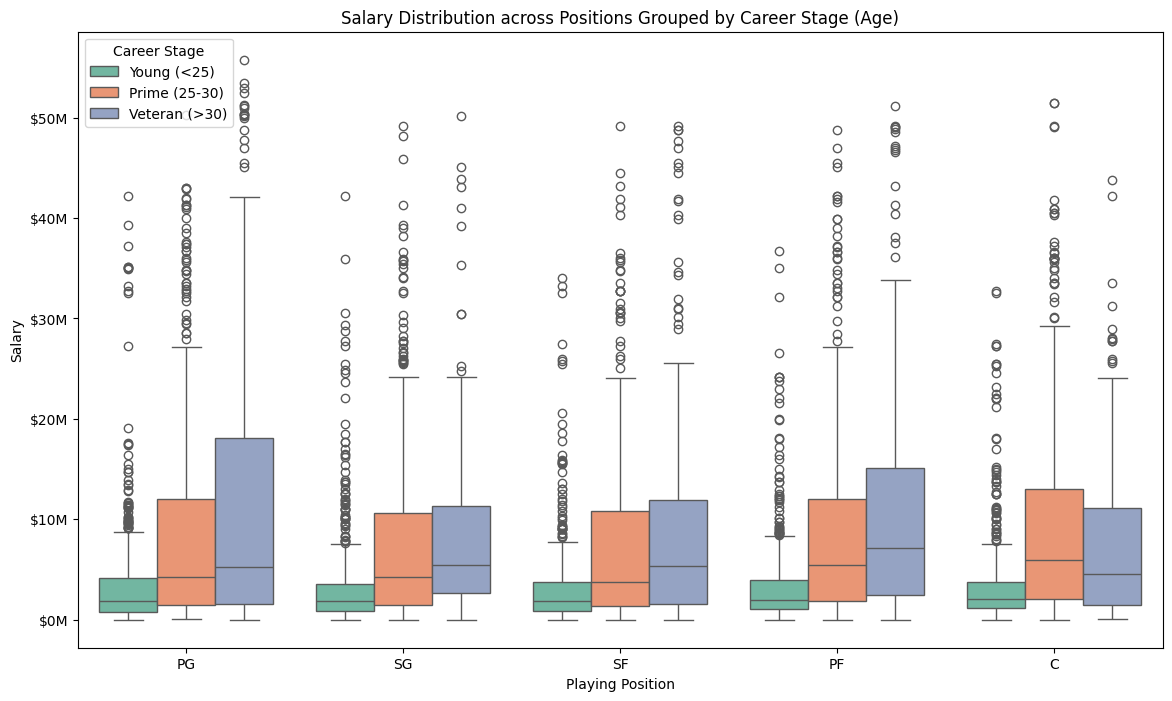

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Helper function to format salary on the Y-axis
def format_salary(x, pos):
    return f"${x*1e-6:.0f}M"

# Create a copy of the dataframe
plot_df = df.copy()
plot_df['Primary_Pos'] = plot_df['Pos'].str.split('-').str[0]

# Plot a grouped boxplot comparing Position and Age Group
plt.figure(figsize=(14, 8))
sns.boxplot(x='Primary_Pos', y='Salary', hue='Age_Group', data=plot_df,
            order=['PG', 'SG', 'SF', 'PF', 'C'],
            hue_order=['Young (<25)', 'Prime (25-30)', 'Veteran (>30)'],
            palette='Set2')

plt.title('Salary Distribution across Positions Grouped by Career Stage (Age)')
plt.xlabel('Playing Position')
plt.ylabel('Salary')
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(format_salary))
plt.legend(title='Career Stage', loc='upper left')

plt.show()

## 6.2 Question 2: Scoring Profiles & Points Per Minute
*Question:* If we engineer a new "Scoring Profile" category (Bench, Role Player, Star) based on minutes played (MP), how do their average points per minute compare?

### 6.2.1 Initial Visualization & Insights
We engineer the "Scoring_Profile" category and calculate a "Points_Per_Minute" metric to observe basic differences in scoring efficiency across player roles.

/tmp/ipykernel_14789/1628541582.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Scoring_Profile', y='PTS_Per_Min', data=q2_df,


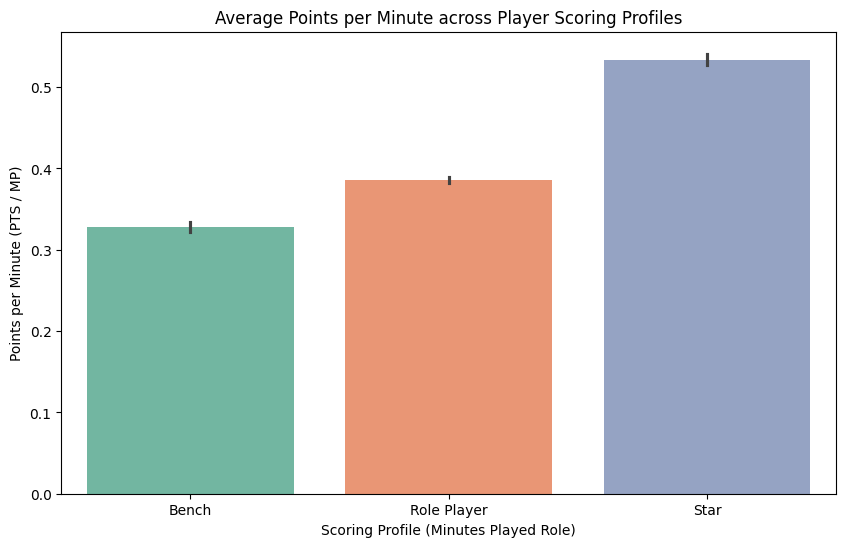

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create copy of dataframe and filter out players with 0 minutes to avoid division by zero
q2_df = df[df['MP'] > 0].copy()

# 1. Feature engineer the "Scoring_Profile" based on Minutes Played (MP)
def get_scoring_profile(mp):
    if mp < 15.0:
        return 'Bench'
    elif mp <= 30.0:
        return 'Role Player'
    else:
        return 'Star'

q2_df['Scoring_Profile'] = q2_df['MP'].apply(get_scoring_profile)

# 2. Feature created is "Points_Per_Minute" (PTS / MP) which shows the scoring efficiency of a player
q2_df['PTS_Per_Min'] = q2_df['PTS'] / q2_df['MP']

# 3. Plot initial barplot comparing points per minute averages
plt.figure(figsize=(10, 6))
sns.barplot(x='Scoring_Profile', y='PTS_Per_Min', data=q2_df,
            order=['Bench', 'Role Player', 'Star'], palette='Set2')

plt.title('Average Points per Minute across Player Scoring Profiles')
plt.xlabel('Scoring Profile (Minutes Played Role)')
plt.ylabel('Points per Minute (PTS / MP)')

plt.show()

### 6.2.2 Refined Visualization (Filtering Outliers & Adding Position)
We refine our analysis by filtering out small-sample noise (excluding players with fewer than 10 games) and splitting our points-per-minute distributions across primary positions to see if role efficiency is position-dependent.

/tmp/ipykernel_14789/2831380928.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Scoring_Profile', data=q2_refined,


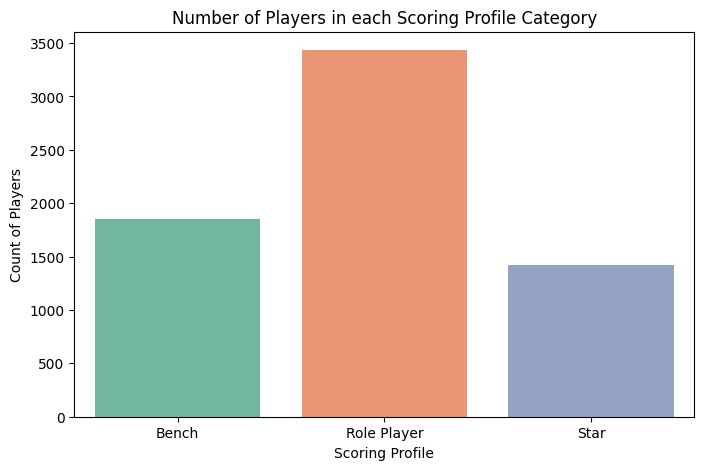

In [ ]:
# Countplot to show how many players fall into each Scoring Profile category
plt.figure(figsize=(8, 5))
# 1. Filter dataset: keep only players with at least 10 games played to remove small-sample noise
q2_refined = df[(df['G'] >= 10) & (df['MP'] > 0)].copy()

# 2. Re-apply our feature engineering steps on the cleaned data
q2_refined['Scoring_Profile'] = q2_refined['MP'].apply(get_scoring_profile)
q2_refined['PTS_Per_Min'] = q2_refined['PTS'] / q2_refined['MP']
q2_refined['Primary_Pos'] = q2_refined['Pos'].str.split('-').str[0]

sns.countplot(x='Scoring_Profile', data=q2_refined,
              order=['Bench', 'Role Player', 'Star'], palette='Set2')

plt.title('Number of Players in each Scoring Profile Category')
plt.xlabel('Scoring Profile')
plt.ylabel('Count of Players')
plt.show()

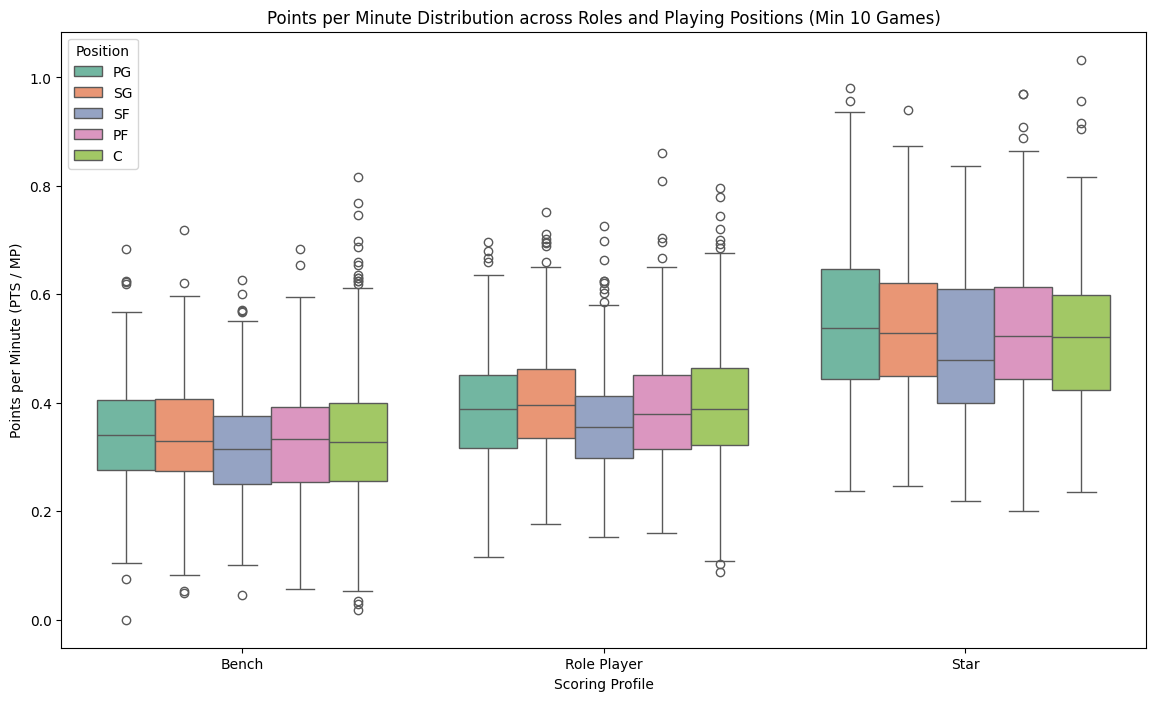

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filter dataset: keep only players with at least 10 games played to remove small-sample noise
q2_refined = df[(df['G'] >= 10) & (df['MP'] > 0)].copy()

# 2. Re-apply our feature engineering steps on the cleaned data
q2_refined['Scoring_Profile'] = q2_refined['MP'].apply(get_scoring_profile)
q2_refined['PTS_Per_Min'] = q2_refined['PTS'] / q2_refined['MP']
q2_refined['Primary_Pos'] = q2_refined['Pos'].str.split('-').str[0]

# 3. make a grouped boxplot comparing role efficiency across positions
plt.figure(figsize=(14, 8))
sns.boxplot(x='Scoring_Profile', y='PTS_Per_Min', hue='Primary_Pos', data=q2_refined,
            order=['Bench', 'Role Player', 'Star'],
            hue_order=['PG', 'SG', 'SF', 'PF', 'C'], palette='Set2')

plt.title('Points per Minute Distribution across Roles and Playing Positions (Min 10 Games)')
plt.xlabel('Scoring Profile')
plt.ylabel('Points per Minute (PTS / MP)')
plt.legend(title='Position', loc='upper left')

plt.show()

## 6.3 Question 3: Shooting Volume vs. Shooting Efficiency
*Question:* Which metric has a stronger correlation with player salary: shooting volume (FGA) or shooting efficiency (eFG%)?

### 6.3.1 Initial Visualization & Insights
We plot side-by-side scatter plots to visually compare the linear relationship of shooting volume (FGA) and shooting efficiency (eFG%) against player salaries.

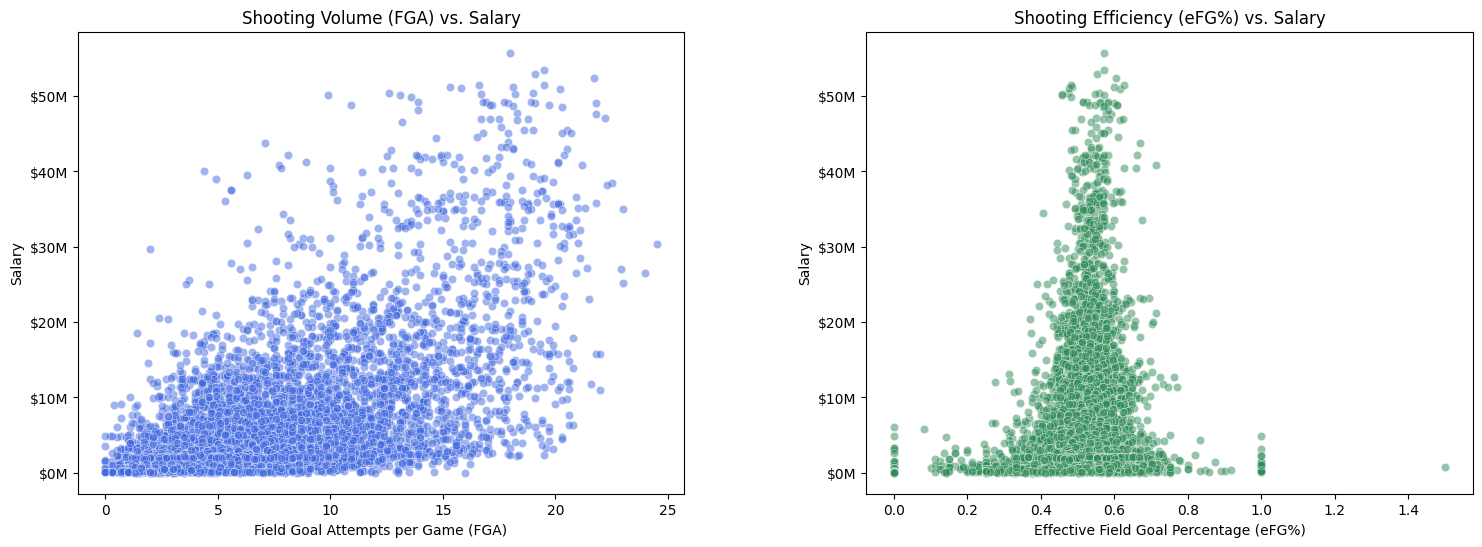

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Helper function to format salary on the Y-axis
def format_salary(x, pos):
    return f"${x*1e-6:.0f}M"

# Create subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 1. Left Plot: Shooting Volume (FGA) vs. Salary
sns.scatterplot(x='FGA', y='Salary', data=df, ax=axes[0], alpha=0.5, color='royalblue')
axes[0].set_title('Shooting Volume (FGA) vs. Salary')
axes[0].set_xlabel('Field Goal Attempts per Game (FGA)')
axes[0].set_ylabel('Salary')
axes[0].yaxis.set_major_formatter(ticker.FuncFormatter(format_salary))

# 2. Right Plot: Shooting Efficiency (eFG%) vs. Salary
sns.scatterplot(x='eFG%', y='Salary', data=df, ax=axes[1], alpha=0.5, color='seagreen')
axes[1].set_title('Shooting Efficiency (eFG%) vs. Salary')
axes[1].set_xlabel('Effective Field Goal Percentage (eFG%)')
axes[1].set_ylabel('Salary')
axes[1].yaxis.set_major_formatter(ticker.FuncFormatter(format_salary))

plt.subplots_adjust(wspace=0.3)
plt.show()

### 6.3.2 Refined Visualization (Filtering & Adding Regression Lines)
We refine the scatter plots by filtering out low-volume outliers (minimum 50 FGA) and fitting OLS regression lines to mathematically compare the strength of the linear relationships.

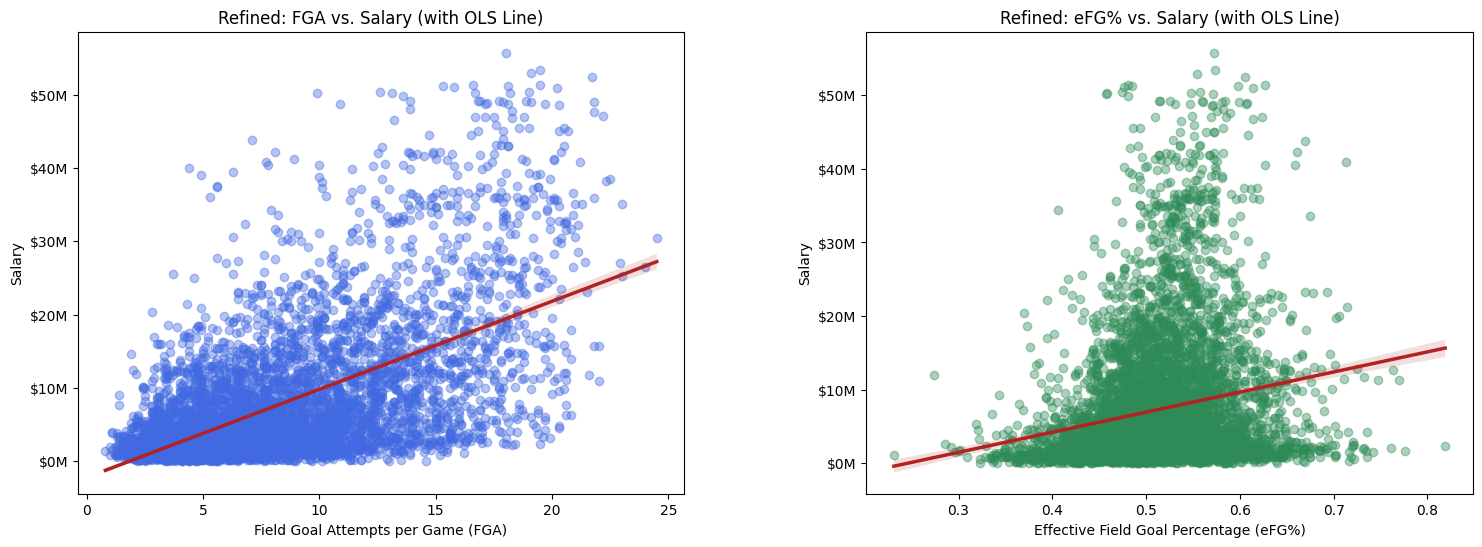

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Helper function to format salary on the Y-axis
def format_salary(x, pos):
    return f"${x*1e-6:.0f}M"

# 1. Filter out low-volume outlier records (Total FGA in the season < 50)
q3_df = df.copy()
q3_df['Total_FGA'] = q3_df['FGA'] * q3_df['G']
q3_refined = q3_df[q3_df['Total_FGA'] >= 50].copy()

# Create subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 2. Left Plot: FGA vs. Salary with OLS Regression Line
sns.regplot(x='FGA', y='Salary', data=q3_refined, ax=axes[0],
            scatter_kws={'alpha': 0.4, 'color': 'royalblue'},
            line_kws={'color': 'firebrick', 'linewidth': 2.5})
axes[0].set_title('Refined: FGA vs. Salary (with OLS Line)')
axes[0].set_xlabel('Field Goal Attempts per Game (FGA)')
axes[0].set_ylabel('Salary')
axes[0].yaxis.set_major_formatter(ticker.FuncFormatter(format_salary))

# 3. Right Plot: eFG% vs. Salary with OLS Regression Line
sns.regplot(x='eFG%', y='Salary', data=q3_refined, ax=axes[1],
            scatter_kws={'alpha': 0.4, 'color': 'seagreen'},
            line_kws={'color': 'firebrick', 'linewidth': 2.5})
axes[1].set_title('Refined: eFG% vs. Salary (with OLS Line)')
axes[1].set_xlabel('Effective Field Goal Percentage (eFG%)')
axes[1].set_ylabel('Salary')
axes[1].yaxis.set_major_formatter(ticker.FuncFormatter(format_salary))

plt.subplots_adjust(wspace=0.3)
plt.show()

# 7. Follow-up Deep-Dive Analysis: The Diminishing Returns Hypothesis
We investigate our self-directed hypothesis regarding the financial "diminishing returns" of high-salaried players in the NBA.

## 7.1 Points per Million Dollars across Salary Tiers
We calculate the financial efficiency metric "Points per Million Dollars" and compare its distribution across Low, Mid, and High salary tiers using a boxplot.

/tmp/ipykernel_14789/4191747966.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Salary_Tier', y='PTS_Per_Million', data=q4_df, palette='Set2')


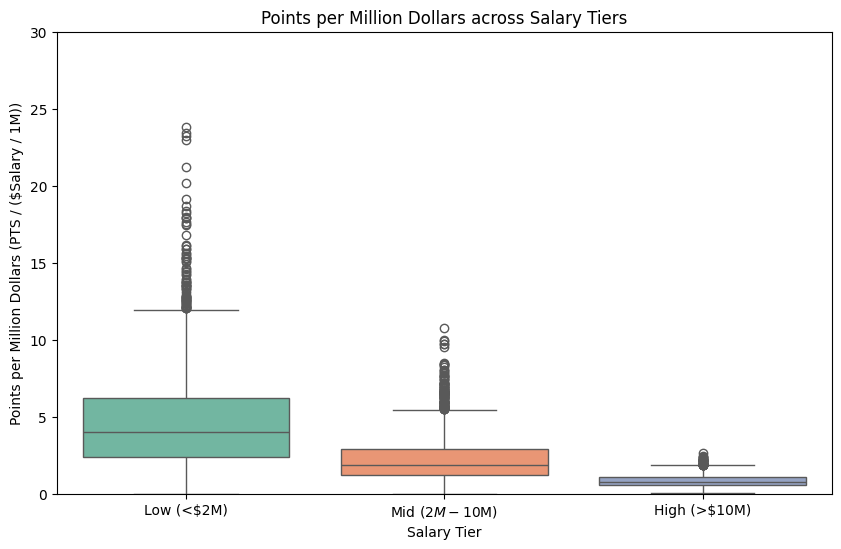

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filter dataset: keep standard contracts (>= $500K) and active players
q4_df = df[(df['Salary'] >= 500000) & (df['MP'] > 0)].copy()

# 2. Re-apply our Salary Tiers on this subset
salary_bins = [0, 2000000, 10000000, 100000000]
salary_labels = ['Low (<$2M)', 'Mid ($2M-$10M)', 'High (>$10M)']
q4_df['Salary_Tier'] = pd.cut(q4_df['Salary'], bins=salary_bins, labels=salary_labels)

# 3. Calculate "Points per Million Dollars" (PTS / (Salary in Millions))
q4_df['PTS_Per_Million'] = q4_df['PTS'] / (q4_df['Salary'] / 1e6)

# 4. Plot the boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(x='Salary_Tier', y='PTS_Per_Million', data=q4_df, palette='Set2')

plt.title('Points per Million Dollars across Salary Tiers')
plt.xlabel('Salary Tier')
plt.ylabel('Points per Million Dollars (PTS / ($Salary / 1M))')

# Restrict the Y-axis range to 0-30 to ignore extreme outliers for clear visual comparison
plt.ylim(0, 30)

plt.show()

# 8. Academic Integrity & AI Tool Disclosure

In compliance with the course guidelines regarding the ethical use of artificial intelligence tools, the following disclosures are made:

### AI Tool Acknowledgment:
* **Tool Utilized:** Gemini AI (by Google).
* **Dates of Utilization:** May 15 to June 4, 2026.

### Scope of Influence & Support:
* **Coding Structure:** The AI assistant was utilized as a supportive aid to plan the workflow layout of the Exploratory Data Analysis (EDA) and to debug visual formatting blocks (specifically using `matplotlib.ticker` to format large numbers to clean millions/thousands scale labels).
* **Mathematical Verifications:** The AI was used to verify the mathematical latex derivations for the skewness and kurtosis proofs.
* **Student Integrity:** All code snippets, data queries, and statistical interpretations were fully reviewed, tested, and processed by the student to reflect original learning and analytical comprehension.